In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [3]:
# b. Load training and testing data
train_data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\FNN and CNN\Sign Language MNIST\sign_mnist_train.csv')
test_data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\FNN and CNN\Sign Language MNIST\sign_mnist_test.csv')

In [4]:
# Separate input features and output labels
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

In [6]:
# Convert labels from 0-24 (excluding 9) to 0-23
y_train = np.where(y_train > 9, y_train - 1, y_train)
y_test = np.where(y_test > 9, y_test - 1, y_test)

# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Class names (J and Z are excluded)
class_names = list("ABCDEFGHIKLMNOPQRSTUVWXY")

Training data: (27455, 784)
Testing data: (7172, 784)


In [7]:
# c. Define Feedforward Neural Network
model = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),
    Dense(64, activation='relu'),
    Dense(24, activation='softmax')
])

C:\Users\SAKSHI\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
# d. Compile and train using Adam optimizer
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
history = model.fit(
    X_train, y_train,
    epochs=11,
    validation_split=0.1
)

Epoch 1/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.0932 - loss: 3.0548 - val_accuracy: 0.1260 - val_loss: 2.8153
Epoch 2/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.1919 - loss: 2.5421 - val_accuracy: 0.2524 - val_loss: 2.2942
Epoch 3/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.2744 - loss: 2.1633 - val_accuracy: 0.3070 - val_loss: 2.0577
Epoch 4/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.3117 - loss: 2.0011 - val_accuracy: 0.3303 - val_loss: 1.9541
Epoch 5/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.3538 - loss: 1.8939 - val_accuracy: 0.3762 - val_loss: 1.8311
Epoch 6/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.3882 - loss: 1.8016 - val_accuracy: 0.4093 - val_loss: 1.7630
Epoch 7/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.4084 - loss: 1.7362 - val_accuracy: 0.4173 - val_loss: 1.7192
Epoch 8/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.4231 - loss: 1.6816 - val_accuracy: 0.

In [10]:
# e. Evaluate the network
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4020 - loss: 1.7676
Test Loss: 1.7675704956054688
Test Accuracy: 0.401979923248291


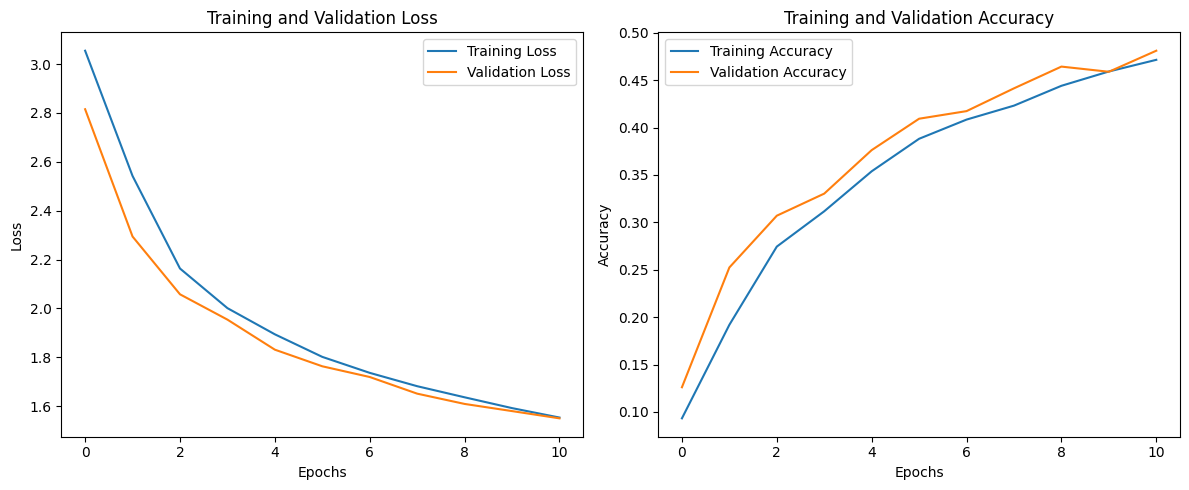

In [11]:
# f. Plot training loss and accuracy
plt.figure(figsize=(12, 5))

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy graph
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


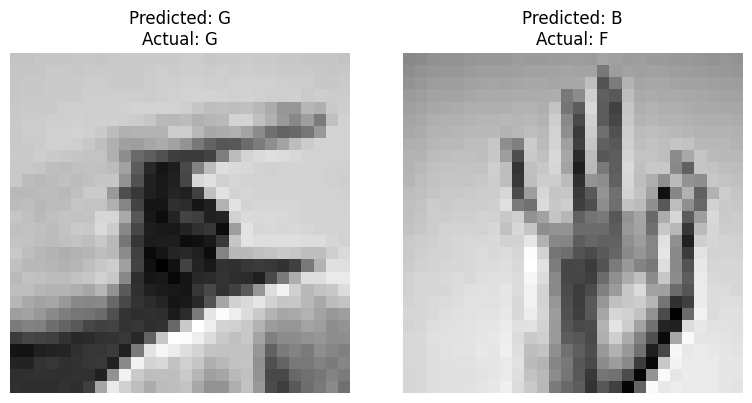

In [12]:
# Display 2 sample predictions
predictions = model.predict(X_test)
predicted_labels = predictions.argmax(axis=1)

plt.figure(figsize=(8, 4))

for i in range(2):
    plt.subplot(1, 2, i+1)

    image = X_test[i].reshape(28, 28)

    plt.imshow(image, cmap='gray')

    plt.title("Predicted: " + class_names[predicted_labels[i]] +
              "\nActual: " + class_names[y_test[i]])

    plt.axis('off')

plt.tight_layout()
plt.show()